<a href="https://colab.research.google.com/github/sahana-labs/customer_segmentation_ml/blob/main/Customer_Segmentation_RFM_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:

!pip -q install ucimlrepo openpyxl


In [17]:

import pandas as pd

url = "https://github.com/dbdmg/data-science-lab/raw/master/datasets/online_retail.csv"

df = pd.read_csv(url, encoding="ISO-8859-1")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


# Data understanding

In [18]:

# Check dataset size
print("Number of rows and columns:", df.shape)

# View column names
print("\nColumn names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Display first five rows
display(df.head())

Number of rows and columns: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


# Data preprocessing

In [19]:

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove rows without customer IDs
df = df.dropna(subset=["CustomerID"]).copy()

# Remove cancelled invoices
df = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Keep valid purchase quantities and prices
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Calculate total purchase value
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned dataset shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())

display(df.head())

Cleaned dataset shape: (392692, 9)
Unique customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34


# Exploratory data analysis

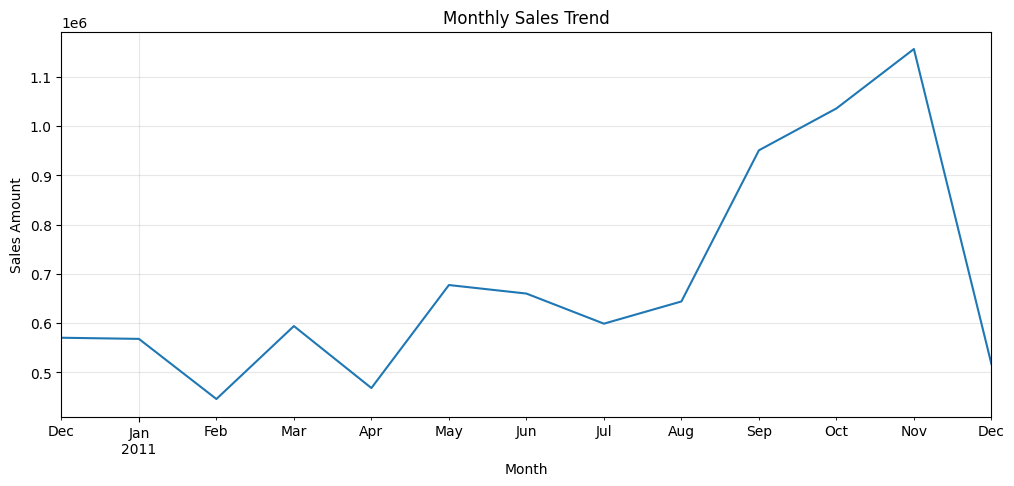

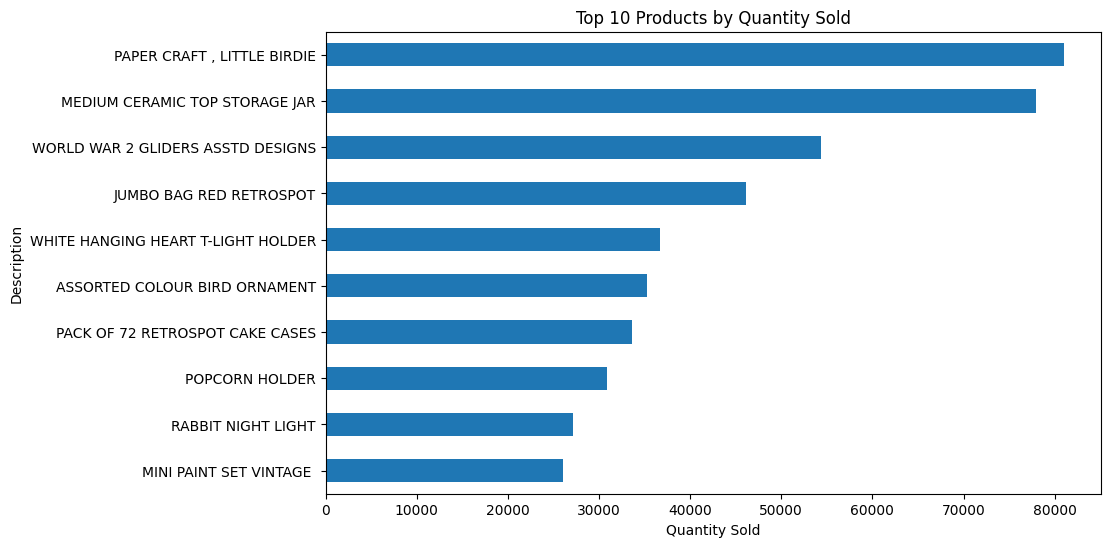

In [20]:

import matplotlib.pyplot as plt
import seaborn as sns

# Monthly sales
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

monthly_sales = (
    df.set_index("InvoiceDate")
      .resample("MS")["TotalAmount"]
      .sum()
)

plt.figure(figsize=(12, 5))
monthly_sales.plot()
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.grid(alpha=0.3)
plt.show()

# Top 10 products by quantity sold
top_products = (
    df.groupby("Description")["Quantity"]
      .sum()
      .nlargest(10)
      .sort_values()
)

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh")
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.show()

# Calculate RFM values

In [21]:

import pandas as pd

# Reference date: one day after the latest transaction
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = (
    df.groupby("CustomerID")
      .agg(
          Recency=(
              "InvoiceDate",
              lambda x: (reference_date - x.max()).days
          ),
          Frequency=("InvoiceNo", "nunique"),
          Monetary=("TotalAmount", "sum")
      )
      .reset_index()
)

print("Customer-level dataset:", rfm.shape)
display(rfm.head(10))

Customer-level dataset: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40
5,12352.0,36,8,2506.04
6,12353.0,204,1,89.00
7,12354.0,232,1,1079.40
8,12355.0,214,1,459.40
9,12356.0,23,3,2811.43


# Prepare the data for machine learning

In [22]:

import numpy as np
from sklearn.preprocessing import StandardScaler

features = ["Recency", "Frequency", "Monetary"]

# Remove invalid values
rfm = rfm.replace([np.inf, -np.inf], np.nan)
rfm = rfm.dropna(subset=features).copy()
rfm = rfm[(rfm[features] >= 0).all(axis=1)].copy()

# Reduce skewness
X_log = np.log1p(rfm[features])

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Features ready for clustering:", X_scaled.shape)

Features ready for clustering: (4338, 3)


# Find the best number of clusters

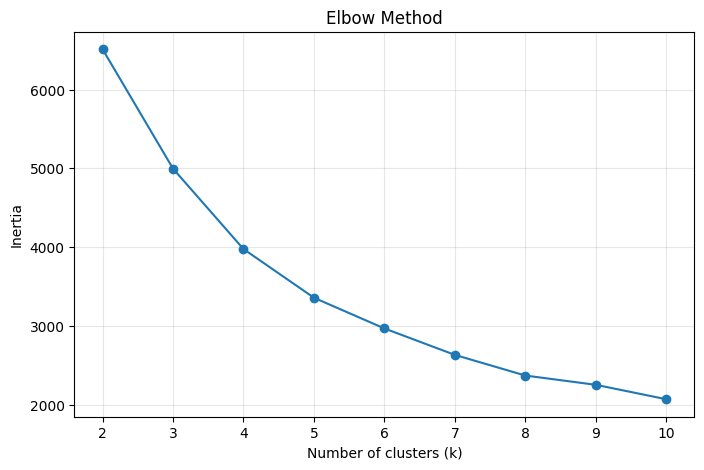

In [23]:

from sklearn.cluster import MiniBatchKMeans

inertias = []
k_values = range(2, 11)

for k in k_values:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=3
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

# Train the K-means model

In [24]:

from sklearn.cluster import KMeans

k = 4

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-means clustering completed!")
print("\nCustomers in each cluster:")
print(rfm["Cluster"].value_counts().sort_index())

K-means clustering completed!

Customers in each cluster:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


## Evaluate the model

In [25]:

from sklearn.metrics import silhouette_score, davies_bouldin_score

# Use a sample for faster evaluation
rng = np.random.default_rng(42)
sample_size = min(10000, len(X_scaled))
sample_idx = rng.choice(
    len(X_scaled), size=sample_size, replace=False
)

X_sample = X_scaled[sample_idx]
labels_sample = rfm["Cluster"].to_numpy()[sample_idx]

silhouette = silhouette_score(X_sample, labels_sample)
db_index = davies_bouldin_score(X_sample, labels_sample)

print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(db_index, 4))

Silhouette Score: 0.3375
Davies-Bouldin Index: 1.0086


## Visualize the customer segments

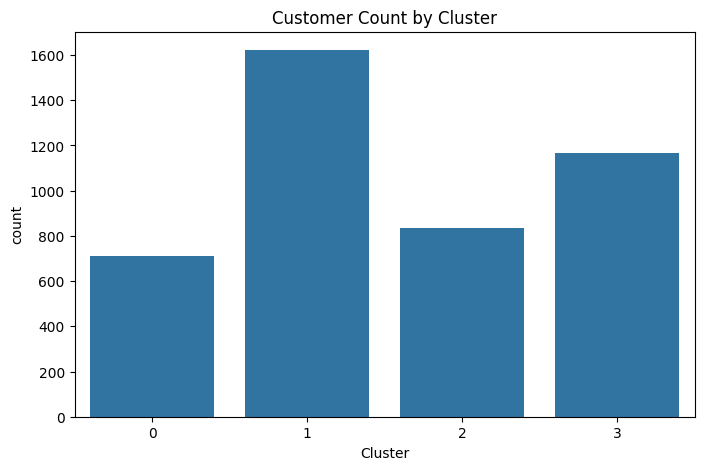

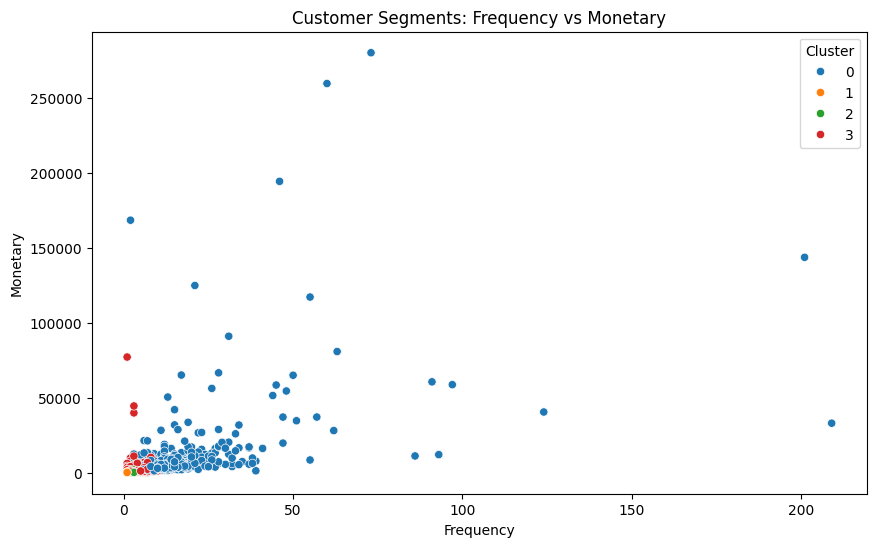

In [26]:

# Cluster sizes
plt.figure(figsize=(8, 5))
sns.countplot(data=rfm, x="Cluster")
plt.title("Customer Count by Cluster")
plt.show()

# Scatter plot using a sample of customers
plot_df = rfm.sample(
    n=min(5000, len(rfm)),
    random_state=42
)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_df,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="tab10"
)
plt.title("Customer Segments: Frequency vs Monetary")
plt.show()

## Interpret the clusters

In [27]:

cluster_summary = (
    rfm.groupby("Cluster")
       .agg(
           Customer_Count=("CustomerID", "count"),
           Average_Recency=("Recency", "mean"),
           Average_Frequency=("Frequency", "mean"),
           Average_Monetary=("Monetary", "mean")
       )
       .round(2)
)

display(cluster_summary)

,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary
Cluster,,,,
0,713,12.17,13.75,8088.02
1,1622,181.51,1.32,341.00
2,837,17.70,2.19,557.32
3,1166,71.64,4.08,1801.78


# Save the final project results

In [28]:

from google.colab import files

rfm.to_csv("customer_segments.csv", index=False)
cluster_summary.to_csv("cluster_summary.csv")

files.download("customer_segments.csv")
files.download("cluster_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Final comparison graph and table

FINAL CLUSTERING ALGORITHM COMPARISON


,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index,Inertia
0,K-Means,4,0.3375,1.0086,3939.0494
1,MiniBatch K-Means,4,0.3328,1.0213,3974.8231
2,Birch,4,0.1849,1.1091,NaN


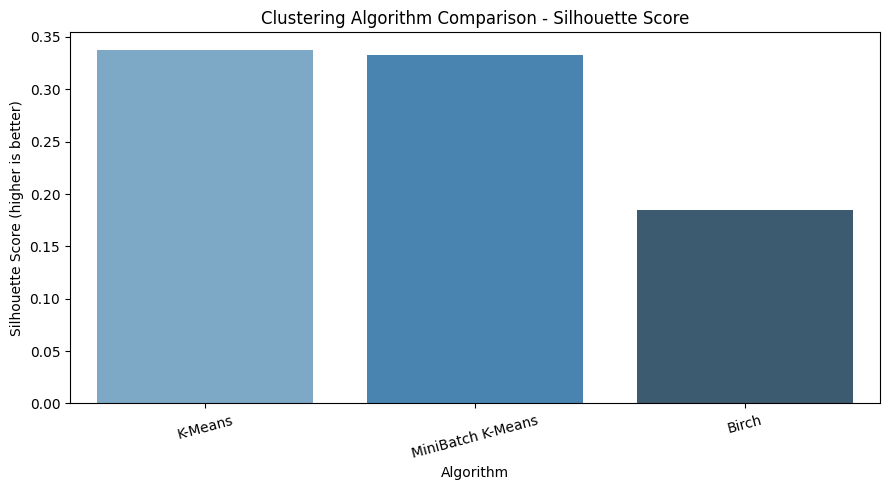

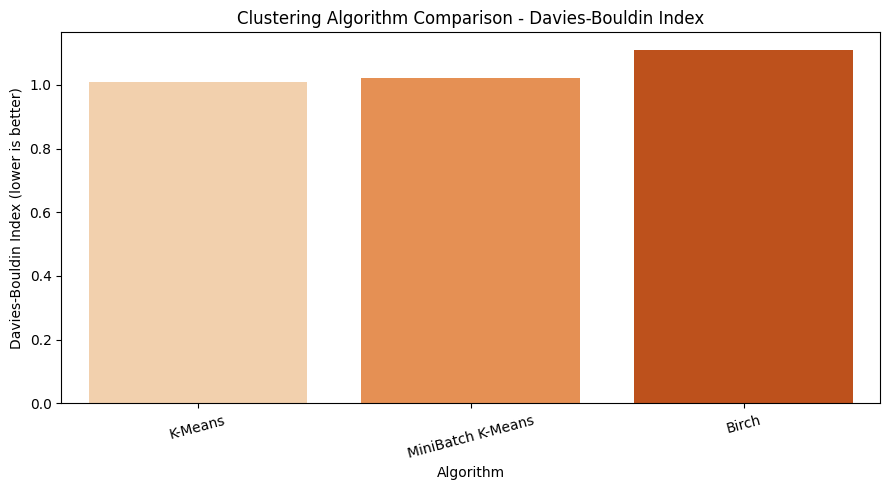

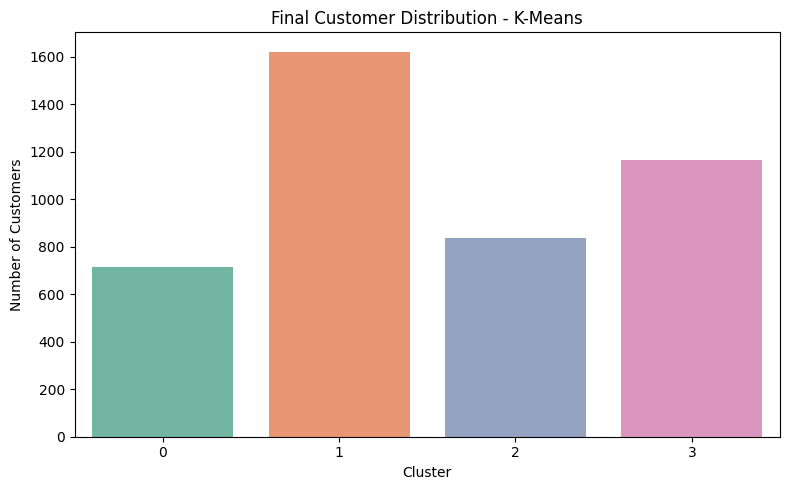

In [29]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, MiniBatchKMeans, Birch
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Use the same scaled RFM features created earlier
# X_scaled and rfm must already exist

k = 4  # Change if your Elbow method suggests another value

models = {
    "K-Means": KMeans(
        n_clusters=k, random_state=42, n_init=10
    ),
    "MiniBatch K-Means": MiniBatchKMeans(
        n_clusters=k, random_state=42,
        batch_size=2048, n_init=5
    ),
    "Birch": Birch(
        n_clusters=k, threshold=0.5
    )
}

# Fixed sample for faster, consistent evaluation
rng = __import__("numpy").random.default_rng(42)
sample_size = min(10000, len(X_scaled))
sample_idx = rng.choice(
    len(X_scaled), size=sample_size, replace=False
)
X_eval = X_scaled[sample_idx]

results = []

for name, model in models.items():
    # Train each model on all customer records
    labels = model.fit_predict(X_scaled)
    labels_eval = labels[sample_idx]

    # Evaluate on the same sample
    sil = silhouette_score(X_eval, labels_eval)
    dbi = davies_bouldin_score(X_eval, labels_eval)

    results.append({
        "Algorithm": name,
        "Clusters": len(set(labels)),
        "Silhouette Score": sil,
        "Davies-Bouldin Index": dbi,
        "Inertia": getattr(model, "inertia_", float("nan"))
    })

    # Save labels for the final selected model
    if name == "K-Means":
        rfm["KMeans_Cluster"] = labels
    elif name == "MiniBatch K-Means":
        rfm["MiniBatch_Cluster"] = labels
    else:
        rfm["Birch_Cluster"] = labels

# Final comparison table
comparison_df = pd.DataFrame(results)

print("FINAL CLUSTERING ALGORITHM COMPARISON")
display(
    comparison_df.round(4).sort_values(
        "Silhouette Score", ascending=False
    ).reset_index(drop=True)
)

# Graph 1: Silhouette scores
plt.figure(figsize=(9, 5))
sns.barplot(
    data=comparison_df,
    x="Algorithm",
    y="Silhouette Score",
    hue="Algorithm",
    palette="Blues_d",
    legend=False
)
plt.title("Clustering Algorithm Comparison - Silhouette Score")
plt.ylabel("Silhouette Score (higher is better)")
plt.xlabel("Algorithm")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Graph 2: Davies-Bouldin index
plt.figure(figsize=(9, 5))
sns.barplot(
    data=comparison_df,
    x="Algorithm",
    y="Davies-Bouldin Index",
    hue="Algorithm",
    palette="Oranges",
    legend=False
)
plt.title("Clustering Algorithm Comparison - Davies-Bouldin Index")
plt.ylabel("Davies-Bouldin Index (lower is better)")
plt.xlabel("Algorithm")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Graph 3: Customer count per cluster for K-Means
plt.figure(figsize=(8, 5))
sns.countplot(
    data=rfm,
    x="KMeans_Cluster",
    hue="KMeans_Cluster",
    palette="Set2",
    legend=False
)
plt.title("Final Customer Distribution - K-Means")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()